In [16]:
#Bước 1. Import thư viện và đọc dữ liệu
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Tìm thư mục gốc project
ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "raw"

train_df = pd.read_csv(DATA_DIR / "youtube_train.csv")
test_df = pd.read_csv(DATA_DIR / "youtube_test.csv")

print("Train:", train_df.shape)
print("Test:", test_df.shape)

display(train_df.head())

Train: (31058, 41)
Test: (7765, 41)


,video_id,channel_id,channel_title,channel_custom_url,channel_published_at,channel_country,channel_subscribers,channel_total_views,channel_video_count,title,...,desc_full_char_len,desc_full_word_count,desc_url_count,desc_hashtag_count,desc_has_timestamps,channel_median_views,viral_ratio,viral_score_log,engagement_rate,is_viral
0,dJL1bE5tNK4,UCPwScwGEE_CXVclsjQQGdUA,Hà Nội Phố,@duyhanoipho,2017-06-20T14:46:24Z,VN,701000,265867620,1994,Check in nhanh 2 bãi tắm ở Biển Hải Tiến...,...,1985,412,5,3,0,11646.0,1.127157,0.754786,0.007617,0
1,_SIFLPYu9-Y,UCTcEd3nksulFiz-iL8wH9-Q,Better Version,@betterversionvn,2021-09-18T10:04:17.220273Z,VN,835000,84870753,228,Để nỗ lực đi đến thịnh vượng thực sự | Better ...,...,2339,428,8,3,1,226767.0,0.457754,0.376897,0.016955,0
2,fQ-TafyfS_8,UC7MGCyKDw8iQX7Vs0-BH9uA,relab,@relab2015,2014-07-27T11:46:49Z,VN,878000,661497984,6798,"Unbox vivo V80 Lite, pin 10.000 mAh, còn gì đặ...",...,0,0,0,0,0,18437.5,0.233316,0.209707,0.021385,0
3,dd4mhNwjp4s,UC0xBYqWa3wZ6yL_Ky9jBGmA,Tờ Mờ Sáng học Lập trình,@tmsanghoclaptrinh,2016-05-12T12:08:37Z,VN,12700,918051,70,Python - Bài 23 - Mảng 2 chiều và các vòng lặp...,...,376,52,4,0,1,1530.5,2.507999,1.255046,0.017443,0
4,qqMoKwGrW1g,UCN7HX0UQQCAgw0K_KnVVkfQ,Plot Phim,@plotphim,2025-08-16T04:56:25.50201Z,VN,10600,8164904,196,[Review Phim] Thám Tử Giải Mã Bí Ẩn Đằng Sau V...,...,492,61,1,5,0,28424.0,1.827652,1.039447,0.008181,0


In [17]:
#Bước 2. Xóa 8 cột Data Leakage

LEAKAGE_COLS = [
    "view_count",
    "like_count",
    "comment_count",
    "crawled_at",
    "channel_median_views",
    "viral_ratio",
    "viral_score_log",
    "engagement_rate"
]

# Tách biến mục tiêu
y_train = train_df["is_viral"].astype(int)
y_test = test_df["is_viral"].astype(int)

# Loại leakage khỏi tập đặc trưng X
X_train = train_df.drop(
    columns=LEAKAGE_COLS + ["is_viral"]
)

X_test = test_df.drop(
    columns=LEAKAGE_COLS + ["is_viral"]
)

# Kiểm tra
assert X_train.columns.equals(X_test.columns)
assert not X_train.columns.isin(LEAKAGE_COLS).any()
assert "is_viral" not in X_train.columns

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Đã loại bỏ 8 cột leakage và tách target!")


X_train: (31058, 32)
X_test: (7765, 32)
Đã loại bỏ 8 cột leakage và tách target!


In [18]:

#Bước 3. Kiểm tra cấu trúc và kiểu dữ liệu

print("Thông tin dữ liệu Train:")
X_train.info()

print("\nThống kê tổng quan:")
display(X_train.describe(include="all").T)

# Kiểm tra số giá trị khác nhau của từng cột
unique_report = pd.DataFrame({
    "dtype": X_train.dtypes.astype(str),
    "nunique": X_train.nunique(dropna=True)
})

display(unique_report.sort_values("nunique"))

# Kiểm tra ID bị trùng
print("Trùng video_id trong Train:",
      train_df["video_id"].duplicated().sum())

print("Trùng video_id trong Test:",
      test_df["video_id"].duplicated().sum())

print("Video trùng giữa Train/Test:",
      len(set(train_df["video_id"])
          & set(test_df["video_id"])))


Thông tin dữ liệu Train:
<class 'pandas.DataFrame'>
RangeIndex: 31058 entries, 0 to 31057
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   video_id                31058 non-null  str  
 1   channel_id              31058 non-null  str  
 2   channel_title           31058 non-null  str  
 3   channel_custom_url      31058 non-null  str  
 4   channel_published_at    31058 non-null  str  
 5   channel_country         31058 non-null  str  
 6   channel_subscribers     31058 non-null  int64
 7   channel_total_views     31058 non-null  int64
 8   channel_video_count     31058 non-null  int64
 9   title                   31058 non-null  str  
 10  description             26099 non-null  str  
 11  tags                    22049 non-null  str  
 12  tag_count               31058 non-null  int64
 13  category_id             31058 non-null  int64
 14  category_name           31058 non-null  str  
 15  publi

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
video_id,31058,31058,dJL1bE5tNK4,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
channel_id,31058,223,UCTcEd3nksulFiz-iL8wH9-Q,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
channel_title,31058,223,Better Version,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
channel_custom_url,31058,223,@betterversionvn,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
channel_published_at,31058,223,2021-09-18T10:04:17.220273Z,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
channel_country,31058,5,VN,29478,NaN,NaN,NaN,NaN,NaN,NaN,NaN
channel_subscribers,31058.0,NaN,NaN,NaN,865953.45048,1987179.593527,15.0,31700.0,144000.0,702000.0,12200000.0
channel_total_views,31058.0,NaN,NaN,NaN,405064610.010271,999605748.225644,13751.0,8374423.0,49999097.0,238830184.0,6776118194.0
channel_video_count,31058.0,NaN,NaN,NaN,3084.755039,9479.017264,11.0,294.0,859.0,2258.0,92398.0
title,31058,30352,XEM NGAY ĐẦY ĐỦ TRÊN KÊNH ⁨@DomDomStudios⁩,101,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,dtype,nunique
dimension,str,1
caption,bool,2
desc_has_timestamps,int64,2
licensed_content,bool,2
definition,str,2
made_for_kids,bool,2
channel_country,str,5
default_language,str,5
default_audio_language,str,10
category_name,str,13


Trùng video_id trong Train: 0
Trùng video_id trong Test: 0
Video trùng giữa Train/Test: 0


- dimension chỉ có một giá trị 2d, nên không cung cấp khả năng phân biệt video.
- duration_iso và duration_sec biểu diễn cùng một thông tin thời lượng; ưu tiên giữ cột số.
- category_id và category_name cùng mô tả danh mục; chỉ cần dùng một cách biểu diễn.
- Các cột định danh như video_id không nên dùng trực tiếp làm đặc trưng dự đoán.

,Missing_Count,Missing_Percent
tags,9009,29.01
default_audio_language,6168,19.86
description,4959,15.97
topic_categories,3859,12.43


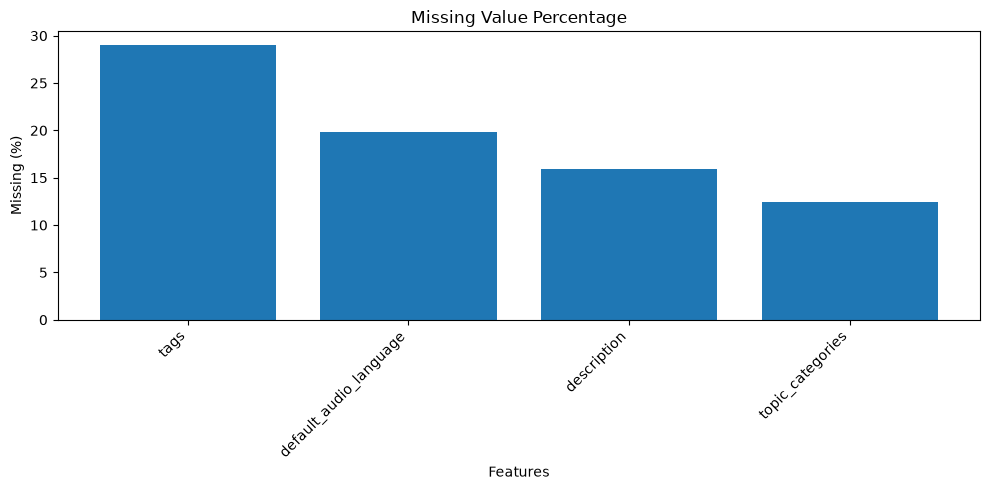

In [19]:

#Bước 4. Phân tích dữ liệu thiếu (Missing Values)

missing_count = X_train.isna().sum()

missing_percent = (
    missing_count / len(X_train) * 100
).round(2)

missing_report = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percent": missing_percent
})

missing_report = missing_report[
    missing_report["Missing_Count"] > 0
].sort_values("Missing_Percent", ascending=False)

display(missing_report)

# Vẽ biểu đồ
plt.figure(figsize=(10, 5))

plt.bar(
    missing_report.index,
    missing_report["Missing_Percent"]
)

plt.title("Missing Value Percentage")
plt.xlabel("Features")
plt.ylabel("Missing (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Dữ liệu thiếu chủ yếu xuất hiện ở các cột dạng văn bản và danh mục. Chưa cần thực hiện imputation tại bước EDA; thay vào đó, xác định phương pháp xử lý phù hợp trong Preprocessing.

Số lượng từng lớp:
is_viral
0    25355
1     5703
Name: count, dtype: int64

Tỷ lệ phần trăm:
is_viral
0    81.64
1    18.36
Name: proportion, dtype: float64


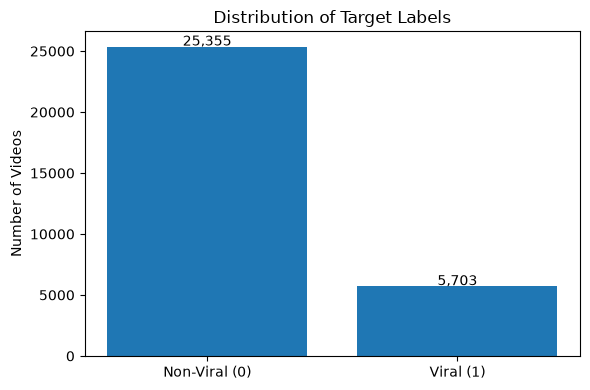

In [20]:
#Bước 5. Phân tích sự mất cân bằng của nhãn


label_count = y_train.value_counts().sort_index()
label_percent = (
    y_train.value_counts(normalize=True)
    .sort_index() * 100
)

print("Số lượng từng lớp:")
print(label_count)

print("\nTỷ lệ phần trăm:")
print(label_percent.round(2))

plt.figure(figsize=(6, 4))

bars = plt.bar(
    ["Non-Viral (0)", "Viral (1)"],
    label_count.values
)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 100,
        f"{int(bar.get_height()):,}",
        ha="center"
    )

plt.title("Distribution of Target Labels")
plt.ylabel("Number of Videos")
plt.tight_layout()
plt.show()


Tập Train có khoảng 81,64% video không viral và 18,36% video viral.

Kết luận: Đây là bài toán phân loại mất cân bằng ở mức đáng chú ý. Khi huấn luyện XGBoost, bạn sẽ cần theo dõi PR-AUC, F1, Recall và Precision thay vì chỉ dựa vào Accuracy.

,count,mean,std,min,25%,50%,75%,max
duration_sec,31058.0,1499.182948,3836.279164,3.0,60.0,391.0,1237.0,43191.0
tag_count,31058.0,13.408236,11.547616,0.0,0.0,14.0,23.0,65.0


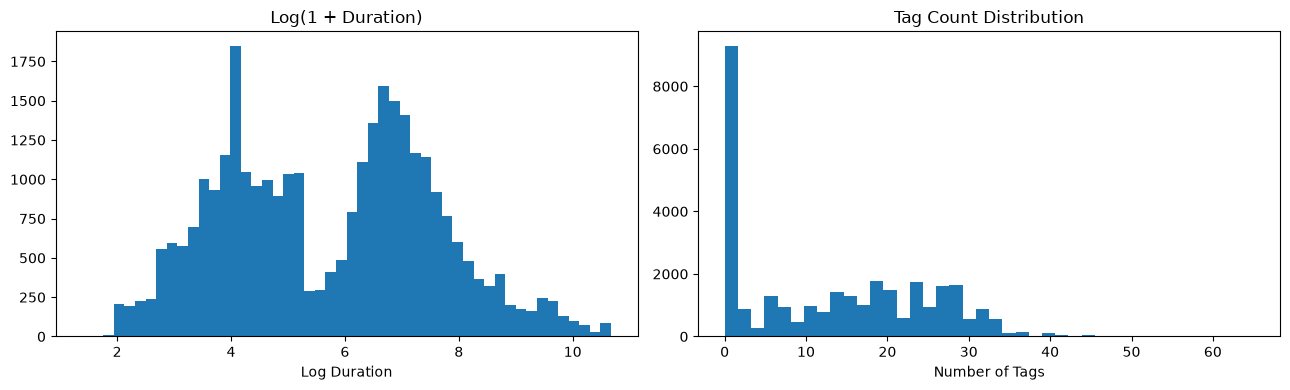

In [21]:
#Bước 6. Khám phá phân phối các đặc trưng số


NUMERIC_EDA_COLS = [
    "duration_sec",
    "tag_count"
]

display(
    X_train[NUMERIC_EDA_COLS].describe().T
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Thời lượng có phân phối lệch phải
axes[0].hist(
    np.log1p(X_train["duration_sec"].clip(lower=0)),
    bins=50
)
axes[0].set_title("Log(1 + Duration)")
axes[0].set_xlabel("Log Duration")

# Phân phối số lượng tags
axes[1].hist(
    X_train["tag_count"].dropna(),
    bins=40
)
axes[1].set_title("Tag Count Distribution")
axes[1].set_xlabel("Number of Tags")

plt.tight_layout()
plt.show()


Thời lượng video phân phối lệch phải: đa số video tương đối ngắn nhưng một số kéo dài nhiều giờ.

Bước 7. Phân tích mối liên hệ giữa Feature và nhãn viral

,total_videos,viral_rate,viral_rate_pct
category_name,,,
Music,795,0.261635,26.163522
Film & Animation,1520,0.259211,25.921053
Gaming,3445,0.229608,22.960813
Science & Technology,3624,0.218267,21.826711
Travel & Events,1500,0.186667,18.666667
Entertainment,3590,0.179109,17.910864
Education,4560,0.177851,17.785088
Sports,637,0.167975,16.797488
News & Politics,1008,0.164683,16.468254


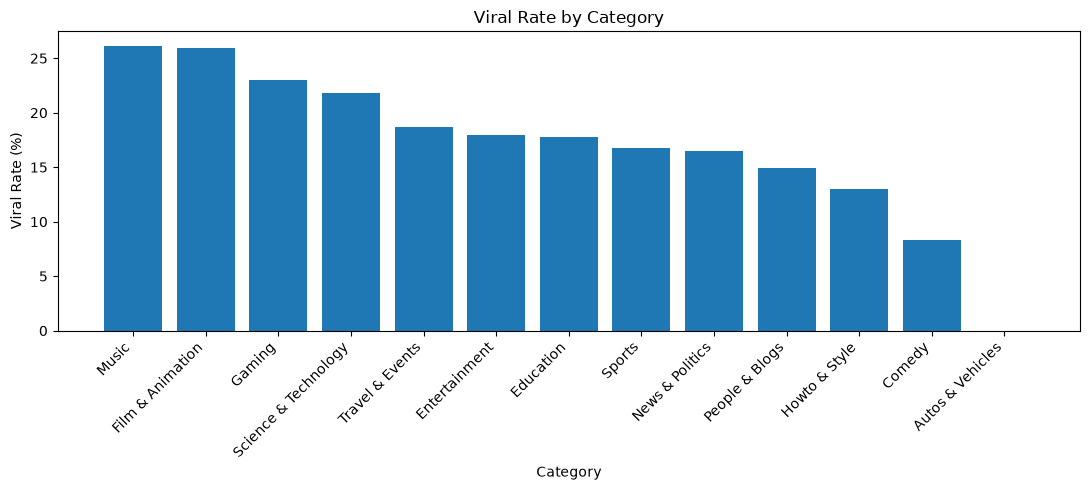

In [22]:
# 7.1. Phân tích theo danh mục video


eda_df = X_train.copy()
eda_df["is_viral"] = y_train

category_stats = (
    eda_df.groupby("category_name")
    .agg(
        total_videos=("is_viral", "size"),
        viral_rate=("is_viral", "mean")
    )
    .sort_values("viral_rate", ascending=False)
)

category_stats["viral_rate_pct"] = (
    category_stats["viral_rate"] * 100
)

display(category_stats)

plt.figure(figsize=(11, 5))

plt.bar(
    category_stats.index,
    category_stats["viral_rate_pct"]
)

plt.title("Viral Rate by Category")
plt.xlabel("Category")
plt.ylabel("Viral Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


duration_sec         tag_count       
                 mean median       mean median
is_viral                                      
0         1448.016013  247.0  12.877500   13.0
1         1726.666316  741.0  15.767841   17.0

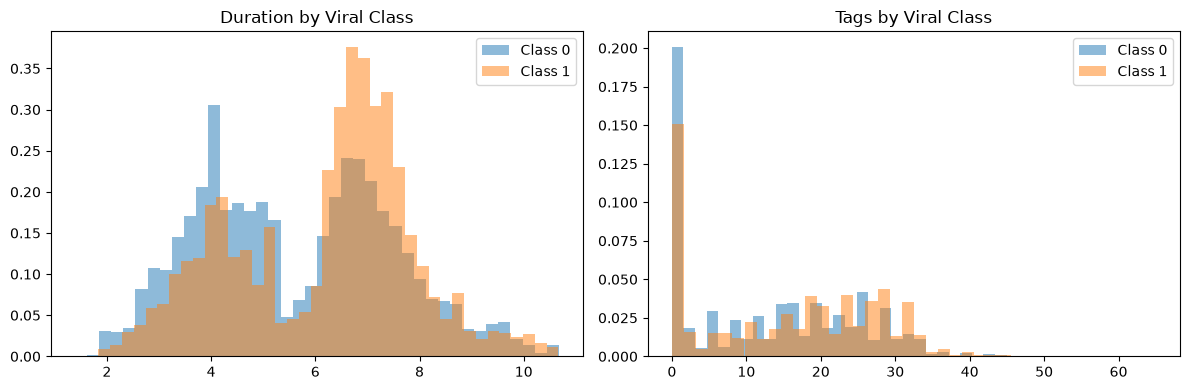

In [23]:
#7.2. So sánh thời lượng và số tag giữa hai lớp


comparison = (
    eda_df.groupby("is_viral")[
        ["duration_sec", "tag_count"]
    ]
    .agg(["mean", "median"])
)

display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for label in [0, 1]:
    subset = eda_df[
        eda_df["is_viral"] == label
    ]

    axes[0].hist(
        np.log1p(subset["duration_sec"]),
        bins=40,
        alpha=0.5,
        density=True,
        label=f"Class {label}"
    )

    axes[1].hist(
        subset["tag_count"],
        bins=40,
        alpha=0.5,
        density=True,
        label=f"Class {label}"
    )

axes[0].set_title("Duration by Viral Class")
axes[1].set_title("Tags by Viral Class")

for ax in axes:
    ax.legend()

plt.tight_layout()
plt.show()


Bước 8. Kiểm tra dữ liệu bất thường và nguy cơ leakage còn lại

In [24]:
#8.1. Kiểm tra Tags không nhất quán


inconsistent_tags = train_df.loc[
    train_df["tags"].isna()
    & train_df["tag_count"].gt(0),
    ["video_id", "tag_count"]
]

print("Số bản ghi bất nhất:",
      len(inconsistent_tags))

display(inconsistent_tags.head(10))


Số bản ghi bất nhất: 126


,video_id,tag_count
126,ENWOfqXfGrA,1
207,-evrMdZ5K3U,1
280,0WaT_i9R0tQ,1
500,4uxLJLLY0ns,1
517,fWqIa0-3Wu8,1
534,7ara2zJsTUE,1
1352,x_Q-HmkvcsA,1
1573,0tbYOP8_jnQ,1
1719,7_-MVz4YCE8,1
1731,svEqoNXJDjo,1


Dữ liệu thực tế có 126 bản ghi Train và 31 bản ghi Test mà tags bị thiếu nhưng tag_count vẫn lớn hơn 0.

Điều này không nhất thiết có nghĩa là tag_count sai. Có thể chuỗi tags bị thiếu trong file xuất, trong khi số lượng tags được ghi nhận riêng từ dữ liệu gốc.

Ở Preprocessing, mình sẽ giữ tag_count và bổ sung một cờ cho biết chuỗi tags có tồn tại hay không.

In [25]:
#8.2. Kiểm tra phần mô tả bị cắt ngắn


visible_desc_len = (
    train_df["description"].fillna("").str.len()
)

truncated_count = (
    train_df["desc_full_char_len"] > visible_desc_len
).sum()

print("Bản ghi có mô tả bị cắt:",
      truncated_count)

print("Bản ghi có mô tả hiển thị dài 500 ký tự:",
      (visible_desc_len == 500).sum())


Bản ghi có mô tả bị cắt: 18953
Bản ghi có mô tả hiển thị dài 500 ký tự: 19102


In [26]:
# 8.3. Kiểm tra sự trùng lặp kênh giữa Train/Test


train_channels = set(train_df["channel_id"])
test_channels = set(test_df["channel_id"])

print("Số kênh Train:", len(train_channels))
print("Số kênh Test:", len(test_channels))

print(
    "Số kênh trùng:",
    len(train_channels & test_channels)
)

# Phân bố năm đăng trên Train
published = pd.to_datetime(
    X_train["published_at"],
    utc=True,
    errors="coerce",
    format="mixed"
)

year_counts = (
    published.dt.year.value_counts().sort_index()
)

display(year_counts.to_frame("video_count"))


Số kênh Train: 223
Số kênh Test: 223
Số kênh trùng: 223


,video_count
published_at,
2014,3
2015,20
2016,30
2017,23
2018,94
2019,91
2020,401
2021,647
2022,848


- Nếu đánh giá trên các kênh đã biết, Test hiện tại có thể phù hợp với mục tiêu đó.
- Nếu muốn biết mô hình có dự đoán tốt cho kênh mới hay video tương lai, cần có thêm phương pháp đánh giá theo kênh hoặc theo thời gian.

# Bước 9. Tổng hợp kết luận EDA

### EDA Conclusions — XGBoost

1. **Dataset:** Train có 31.058 video, Test có 7.765 video, với 41 cột ban đầu.
2. **Data Leakage:** Loại bỏ 8 cột liên quan đến kết quả sau đăng và thời điểm crawl; tách `is_viral` làm target.
3. **Class Imbalance:** Lớp viral chiếm khoảng 18,36% trong Train. Cần ưu tiên PR-AUC, F1, Precision và Recall.
4. **Missing Values:** Tập trung tại `tags`, `description`, `default_audio_language` và `topic_categories`.
5. **Numerical Features:** `duration_sec` có phân phối lệch phải; không tự động xóa outliers nếu chưa xác minh.
6. **Categorical Features:** `category_name` có liên hệ thống kê với tỷ lệ viral và là ứng viên để One-Hot Encoding.
7. **Text Data:** Mô tả video có hiện tượng cắt ngắn; cần lưu ý khi trích xuất đặc trưng NLP.
8. **Validation Strategy:** Nên bổ sung Group-based Validation theo `channel_id` để hạn chế đánh giá quá lạc quan.
9. **Feature Availability:** Các chỉ số kênh ghi nhận tại thời điểm crawl chưa được xác minh là giá trị tại thời điểm đăng video, nên tạm loại khỏi baseline nghiêm ngặt chống leakage.

**Next step:** Xây dựng Preprocessing Pipeline cho XGBoost trên dữ liệu Train, không fit các bộ biến đổi trên Validation hoặc Test.